Device: cuda
GPU: Tesla T4


100%|██████████| 792M/792M [00:30<00:00, 25.9MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 13.8MB/s]


Classes: 37
Train: 740 Validation: 185 Test: 185

MODEL: ResNet50 CNN
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 157MB/s]


Total parameters: 23,583,845
Trainable parameters: 75,813
Epoch 1/2 | Train Loss: 3.3606 | Train Acc: 15.00% | Val Loss: 2.9760 | Val Acc: 64.32% | Time: 0.13 min
Epoch 2/2 | Train Loss: 2.4965 | Train Acc: 78.51% | Val Loss: 2.4172 | Val Acc: 76.76% | Time: 0.09 min

TEST RESULTS
Test Loss: 2.4497
Accuracy: 72.97%
Macro Precision: 78.25%
Macro Recall: 72.97%
Macro F1: 72.34%
Total model time: 0.26 minutes

MODEL: ViT-B/16
Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:02<00:00, 138MB/s]


Total parameters: 85,827,109
Trainable parameters: 28,453
Epoch 1/2 | Train Loss: 2.8799 | Train Acc: 45.41% | Val Loss: 1.9559 | Val Acc: 81.62% | Time: 0.19 min
Epoch 2/2 | Train Loss: 1.3333 | Train Acc: 87.30% | Val Loss: 0.9749 | Val Acc: 87.57% | Time: 0.19 min

TEST RESULTS
Test Loss: 0.9479
Accuracy: 88.11%
Macro Precision: 90.68%
Macro Recall: 88.11%
Macro F1: 87.69%
Total model time: 0.50 minutes

FINAL COMPARISON
ResNet50 CNN: Accuracy=72.97% | Precision=78.25% | Recall=72.97% | F1=72.34% | Time=0.26 min
ViT-B/16: Accuracy=88.11% | Precision=90.68% | Recall=88.11% | F1=87.69% | Time=0.50 min


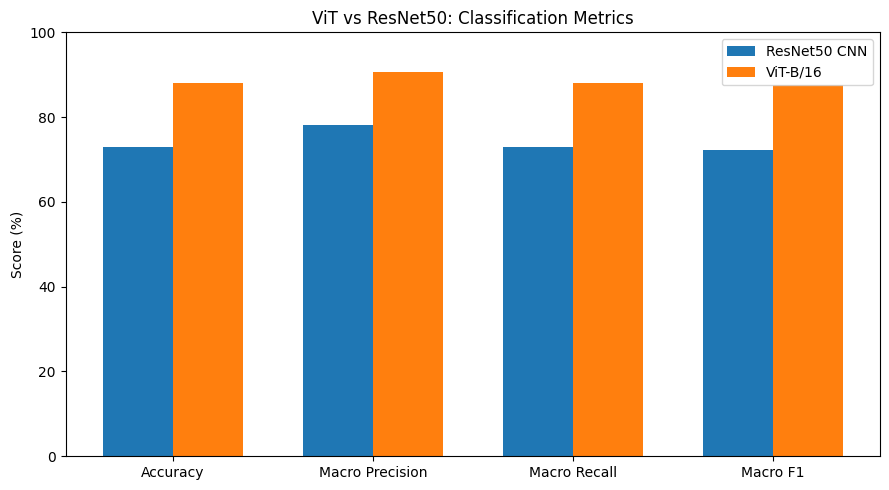

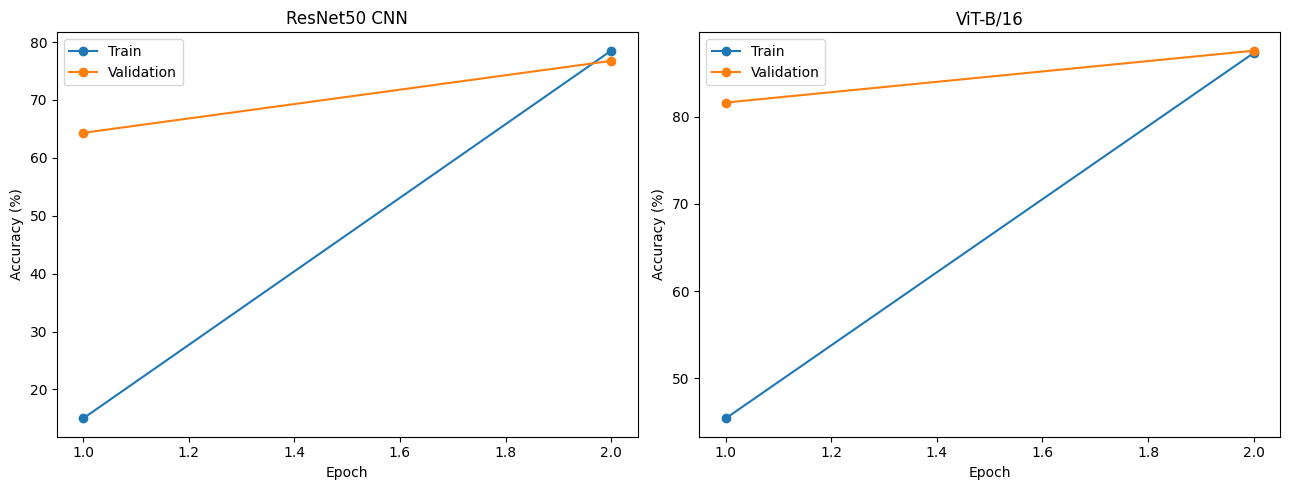

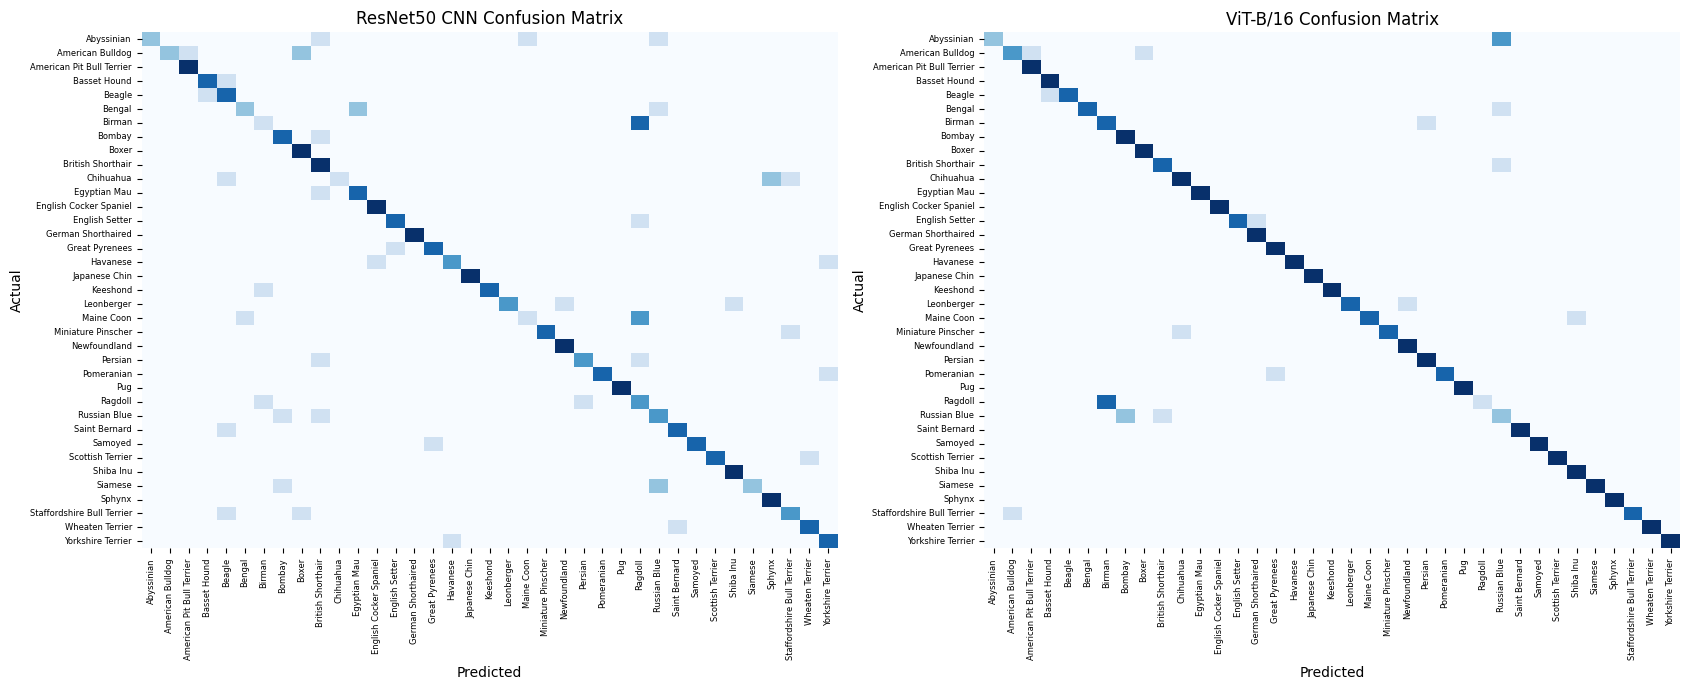


Classification report: ResNet50 CNN
                            precision    recall  f1-score   support

                Abyssinian       1.00      0.40      0.57         5
          American Bulldog       1.00      0.40      0.57         5
 American Pit Bull Terrier       0.83      1.00      0.91         5
              Basset Hound       0.80      0.80      0.80         5
                    Beagle       0.50      0.80      0.62         5
                    Bengal       0.67      0.40      0.50         5
                    Birman       0.33      0.20      0.25         5
                    Bombay       0.67      0.80      0.73         5
                     Boxer       0.62      1.00      0.77         5
         British Shorthair       0.50      1.00      0.67         5
                 Chihuahua       1.00      0.20      0.33         5
              Egyptian Mau       0.67      0.80      0.73         5
    English Cocker Spaniel       0.83      1.00      0.91         5
          

In [1]:

!pip install -q torch torchvision scikit-learn matplotlib seaborn
import os,time,random,copy,gc
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models
import torchvision.transforms as transforms
import torchvision.datasets as datasets
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import Dataset,DataLoader,Subset
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report
SEED=42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
IMAGE_SIZE=224
BATCH_SIZE=64
EPOCHS=2
LEARNING_RATE=0.001
TRAIN_PER_CLASS=20
VAL_PER_CLASS=5
TEST_PER_CLASS=5
NUM_CLASSES=37
DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:",DEVICE)
if torch.cuda.is_available(): print("GPU:",torch.cuda.get_device_name(0))
train_transform=transforms.Compose([transforms.Resize((IMAGE_SIZE,IMAGE_SIZE)),transforms.RandomHorizontalFlip(),transforms.ToTensor(),transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])
eval_transform=transforms.Compose([transforms.Resize((IMAGE_SIZE,IMAGE_SIZE)),transforms.ToTensor(),transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])
train_raw=datasets.OxfordIIITPet(root="./data",split="trainval",target_types="category",download=True)
test_raw=datasets.OxfordIIITPet(root="./data",split="test",target_types="category",download=True)
class PetDataset(Dataset):
    def __init__(self,base,indices,transform):
        self.base=base
        self.indices=indices
        self.transform=transform
    def __len__(self): return len(self.indices)
    def __getitem__(self,i):
        image,label=self.base[self.indices[i]]
        return self.transform(image),label
def get_labels(dataset):
    if hasattr(dataset,"_labels"): return list(dataset._labels)
    if hasattr(dataset,"targets"): return list(dataset.targets)
    return [dataset[i][1] for i in range(len(dataset))]
def balanced_indices(labels,count):
    grouped={c:[] for c in range(NUM_CLASSES)}
    for i,label in enumerate(labels):
        grouped[int(label)].append(i)
    selected=[]
    for c in range(NUM_CLASSES):
        random.shuffle(grouped[c])
        if len(grouped[c])<count: raise ValueError(f"Not enough images for class {c}")
        selected.extend(grouped[c][:count])
    return selected
train_labels=get_labels(train_raw)
test_labels=get_labels(test_raw)
grouped={c:[] for c in range(NUM_CLASSES)}
for i,label in enumerate(train_labels): grouped[int(label)].append(i)
train_idx=[]
val_idx=[]
for c in range(NUM_CLASSES):
    random.shuffle(grouped[c])
    train_idx.extend(grouped[c][:TRAIN_PER_CLASS])
    val_idx.extend(grouped[c][TRAIN_PER_CLASS:TRAIN_PER_CLASS+VAL_PER_CLASS])
test_idx=balanced_indices(test_labels,TEST_PER_CLASS)
train_ds=PetDataset(train_raw,train_idx,train_transform)
val_ds=PetDataset(train_raw,val_idx,eval_transform)
test_ds=PetDataset(test_raw,test_idx,eval_transform)
pin=DEVICE.type=="cuda"
train_loader=DataLoader(train_ds,batch_size=BATCH_SIZE,shuffle=True,num_workers=2,pin_memory=pin)
val_loader=DataLoader(val_ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=2,pin_memory=pin)
test_loader=DataLoader(test_ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=2,pin_memory=pin)
print("Classes:",NUM_CLASSES)
print("Train:",len(train_ds),"Validation:",len(val_ds),"Test:",len(test_ds))
class_names=[name for name,index in sorted(train_raw.class_to_idx.items(),key=lambda x:x[1])]
def build_resnet():
    model=models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    for p in model.parameters(): p.requires_grad=False
    model.fc=nn.Linear(model.fc.in_features,NUM_CLASSES)
    return model
def build_vit():
    model=models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT)
    for p in model.parameters(): p.requires_grad=False
    model.heads.head=nn.Linear(model.heads.head.in_features,NUM_CLASSES)
    return model
def run_epoch(model,loader,criterion,optimizer=None):
    training=optimizer is not None
    model.train() if training else model.eval()
    total_loss=0
    correct=0
    total=0
    all_preds=[]
    all_labels=[]
    with torch.set_grad_enabled(training):
        for images,labels in loader:
            images=images.to(DEVICE,non_blocking=True)
            labels=labels.to(DEVICE,non_blocking=True)
            if training: optimizer.zero_grad(set_to_none=True)
            outputs=model(images)
            loss=criterion(outputs,labels)
            if training:
                loss.backward()
                optimizer.step()
            total_loss+=loss.item()*labels.size(0)
            preds=outputs.argmax(1)
            correct+=(preds==labels).sum().item()
            total+=labels.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    return total_loss/total,correct/total,all_labels,all_preds
def run_model(name,builder):
    print("\n"+"="*65+"\nMODEL:",name+"\n"+"="*65)
    start=time.time()
    model=builder().to(DEVICE)
    total_params=sum(p.numel() for p in model.parameters())
    trainable_params=sum(p.numel() for p in model.parameters() if p.requires_grad)
    print("Total parameters:",f"{total_params:,}")
    print("Trainable parameters:",f"{trainable_params:,}")
    criterion=nn.CrossEntropyLoss()
    optimizer=optim.Adam((p for p in model.parameters() if p.requires_grad),lr=LEARNING_RATE)
    history={"train_loss":[],"train_acc":[],"val_loss":[],"val_acc":[]}
    for epoch in range(EPOCHS):
        epoch_start=time.time()
        train_loss,train_acc,_,_=run_epoch(model,train_loader,criterion,optimizer)
        val_loss,val_acc,_,_=run_epoch(model,val_loader,criterion)
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} | Train Acc: {train_acc*100:.2f}% | Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}% | Time: {(time.time()-epoch_start)/60:.2f} min")
    test_loss,test_acc,y_true,y_pred=run_epoch(model,test_loader,criterion)
    result={"model":name,"accuracy":accuracy_score(y_true,y_pred),"precision":precision_score(y_true,y_pred,average="macro",zero_division=0),"recall":recall_score(y_true,y_pred,average="macro",zero_division=0),"f1":f1_score(y_true,y_pred,average="macro",zero_division=0),"test_loss":test_loss,"time_min":(time.time()-start)/60,"total_params":total_params,"trainable_params":trainable_params,"history":history,"y_true":y_true,"y_pred":y_pred}
    print("\nTEST RESULTS")
    print(f"Test Loss: {test_loss:.4f}")
    print(f"Accuracy: {result['accuracy']*100:.2f}%")
    print(f"Macro Precision: {result['precision']*100:.2f}%")
    print(f"Macro Recall: {result['recall']*100:.2f}%")
    print(f"Macro F1: {result['f1']*100:.2f}%")
    print(f"Total model time: {result['time_min']:.2f} minutes")
    del model,optimizer,criterion
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return result
results=[]
results.append(run_model("ResNet50 CNN",build_resnet))
results.append(run_model("ViT-B/16",build_vit))
print("\n"+"="*65+"\nFINAL COMPARISON\n"+"="*65)
for r in results:
    print(f"{r['model']}: Accuracy={r['accuracy']*100:.2f}% | Precision={r['precision']*100:.2f}% | Recall={r['recall']*100:.2f}% | F1={r['f1']*100:.2f}% | Time={r['time_min']:.2f} min")
metrics=["accuracy","precision","recall","f1"]
x=np.arange(len(metrics))
width=0.35
plt.figure(figsize=(9,5))
for i,r in enumerate(results):
    plt.bar(x+(i-0.5)*width,[r[m]*100 for m in metrics],width,label=r["model"])
plt.xticks(x,["Accuracy","Macro Precision","Macro Recall","Macro F1"])
plt.ylabel("Score (%)")
plt.ylim(0,100)
plt.title("ViT vs ResNet50: Classification Metrics")
plt.legend()
plt.tight_layout()
plt.show()
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,r in zip(axes,results):
    h=r["history"]
    ax.plot(range(1,EPOCHS+1),[v*100 for v in h["train_acc"]],marker="o",label="Train")
    ax.plot(range(1,EPOCHS+1),[v*100 for v in h["val_acc"]],marker="o",label="Validation")
    ax.set_title(r["model"])
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy (%)")
    ax.legend()
plt.tight_layout()
plt.show()
fig,axes=plt.subplots(1,2,figsize=(17,7))
for ax,r in zip(axes,results):
    cm=confusion_matrix(r["y_true"],r["y_pred"],labels=list(range(NUM_CLASSES)))
    sns.heatmap(cm,ax=ax,cmap="Blues",xticklabels=class_names,yticklabels=class_names,cbar=False)
    ax.set_title(r["model"]+" Confusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.tick_params(axis="x",labelrotation=90,labelsize=6)
    ax.tick_params(axis="y",labelsize=6)
plt.tight_layout()
plt.show()
for r in results:
    print("\nClassification report:",r["model"])
    print(classification_report(r["y_true"],r["y_pred"],labels=list(range(NUM_CLASSES)),target_names=class_names,zero_division=0))
print("\nTotal experiment time:",f"{sum(r['time_min'] for r in results):.2f} minutes")
